In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
hiv_df=pd.read_csv("hiv_global_timeseries.csv")

In [5]:
hiv_cog = hiv_df[hiv_df["country_code"]=='COG']
hiv_cog.head()

,country_code,country_name,year,indicator,indicator_code,value,unit,age_group,sex,source_org,source_dataset,retrieval_date,notes
560,COG,Congo,2010,Antiretroviral therapy coverage among people l...,PERCENT_PLWH,8.46081,percent,0-14,both,UNAIDS,"AIDSinfo Estimates 2026 (bulk CSV, Area Level ...",2026-08-24,NaN
561,COG,Congo,2011,Antiretroviral therapy coverage among people l...,PERCENT_PLWH,9.21805,percent,0-14,both,UNAIDS,"AIDSinfo Estimates 2026 (bulk CSV, Area Level ...",2026-08-24,NaN
562,COG,Congo,2012,Antiretroviral therapy coverage among people l...,PERCENT_PLWH,10.04775,percent,0-14,both,UNAIDS,"AIDSinfo Estimates 2026 (bulk CSV, Area Level ...",2026-08-24,NaN
563,COG,Congo,2013,Antiretroviral therapy coverage among people l...,PERCENT_PLWH,10.26403,percent,0-14,both,UNAIDS,"AIDSinfo Estimates 2026 (bulk CSV, Area Level ...",2026-08-24,NaN
564,COG,Congo,2014,Antiretroviral therapy coverage among people l...,PERCENT_PLWH,12.71248,percent,0-14,both,UNAIDS,"AIDSinfo Estimates 2026 (bulk CSV, Area Level ...",2026-08-24,NaN


In [6]:
print(hiv_cog.dtypes)
print(f"{hiv_cog.shape[0]} lignes et {hiv_cog.shape[1]} colonnes")

country_code       object
country_name       object
year                int64
indicator          object
indicator_code     object
value             float64
unit               object
age_group          object
sex                object
source_org         object
source_dataset     object
retrieval_date     object
notes              object
dtype: object
1617 lignes et 13 colonnes


In [7]:
hiv_cog = hiv_cog.drop(columns=["notes"])
hiv_cog['retrieval_date'] = pd.to_datetime(hiv_cog['retrieval_date'])
print(hiv_cog.dtypes)

country_code              object
country_name              object
year                       int64
indicator                 object
indicator_code            object
value                    float64
unit                      object
age_group                 object
sex                       object
source_org                object
source_dataset            object
retrieval_date    datetime64[ns]
dtype: object


In [8]:
print(f"\n{hiv_cog.isnull().sum()}")
print(f"{hiv_cog.duplicated().sum()}")


country_code       0
country_name       0
year               0
indicator          0
indicator_code     0
value             57
unit               0
age_group          0
sex                0
source_org         0
source_dataset     0
retrieval_date     0
dtype: int64
9


In [9]:
display(hiv_cog[hiv_cog.duplicated(keep=False)])


,country_code,country_name,year,indicator,indicator_code,value,unit,age_group,sex,source_org,source_dataset,retrieval_date
67202,COG,Congo,2022,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67203,COG,Congo,2022,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67204,COG,Congo,2022,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67205,COG,Congo,2022,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67206,COG,Congo,2023,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67207,COG,Congo,2023,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67208,COG,Congo,2023,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67209,COG,Congo,2023,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67210,COG,Congo,2024,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24
67211,COG,Congo,2024,HIV tests performed where results were receive...,HIV_0000000027,NaN,count,all,both,WHO,Global Health Observatory (GHO) OData API,2026-08-24


In [10]:
hiv_cog=hiv_cog.apply(lambda colonne: colonne.str.strip().str.lower() if colonne.dtype=="object" else colonne)

In [11]:
# ==================================================
# Suppressions des doublons
# ==================================================
hiv_cog = hiv_cog.drop_duplicates()
hiv_cog = hiv_cog.reset_index(drop=True)
hiv_cog.duplicated().sum()

np.int64(0)

In [12]:
# ==================================================
# Gestion des valeurs manquantes
# ==================================================

# Isolation des valeurs manquantes
missing_values_df = hiv_cog[hiv_cog['value'].isna()]
display(missing_values_df)

,country_code,country_name,year,indicator,indicator_code,value,unit,age_group,sex,source_org,source_dataset,retrieval_date
438,cog,congo,2022,hiv tests performed where results were receive...,hiv_0000000027,NaN,count,all,both,who,global health observatory (gho) odata api,2026-08-24
439,cog,congo,2023,hiv tests performed where results were receive...,hiv_0000000027,NaN,count,all,both,who,global health observatory (gho) odata api,2026-08-24
440,cog,congo,2024,hiv tests performed where results were receive...,hiv_0000000027,NaN,count,all,both,who,global health observatory (gho) odata api,2026-08-24
1166,cog,congo,2017,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1167,cog,congo,2018,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1168,cog,congo,2019,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1169,cog,congo,2020,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1170,cog,congo,2021,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1171,cog,congo,2022,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24
1172,cog,congo,2023,people living with hiv who have suppressed vir...,viral_load_suppression,NaN,percent,0-14,both,unaids,"aidsinfo estimates 2026 (bulk csv, area level ...",2026-08-24


In [13]:
# suppression des valeurs manquantes
hiv_cog = hiv_cog.dropna()
hiv_cog.isnull().sum()

,0
country_code,0
country_name,0
year,0
indicator,0
indicator_code,0
value,0
unit,0
age_group,0
sex,0
source_org,0


In [14]:
# Exportation du dataset de l'EDA
hiv_cog.to_csv("Donnees_congo.csv")

In [15]:
# Assurons-nous simplement qu'elle est bien au format entier
hiv_cog['year'] = hiv_cog['year'].astype(int)

In [19]:
# ==============================================================================
# CRÉATION & CALCUL DES INDICATEURS
# ==============================================================================

# Prevalence
preva_df = hiv_cog[hiv_cog['indicator_code'].isin(['hiv_0000000001', 'anc_testing', 'hiv_prevalence', "hiv_0000000020", "hiv_0000000026", "mdg_0000000029", 'new_infections',"plwh", "sdghiv" ])]
preva_trend = preva_df.groupby('year')['value'].mean().reset_index()

# Dépistage & Diagnostic (Connaissance du statut sérologique)
testing_df = hiv_cog[hiv_cog['indicator_code'].isin(['hiv_statusknownhiv', 'anc_testing', 'number_plhiv_knowledge_of_status'])]
testing_trend = testing_df.groupby('year')['value'].mean().reset_index()

# Prise en charge médicale (Couverture ARV / Antirétroviraux)
arv_df = hiv_cog[hiv_cog['indicator_code'].isin(['percent_plwh', 'hiv_arvcoverage']) & (hiv_cog['sex'] == 'both')]
arv_trend = arv_df.groupby('year')['value'].mean().reset_index()

# Incidence du VIH (Nouveaux cas)
nincidence_df = hiv_cog[hiv_cog['indicator_code'].isin(['new_infections', 'hiv_0000000026']) & (hiv_cog['sex'] == 'both')]
incidence_trend = nincidence_df.groupby('year')['value'].sum().reset_index()

# Impact sur la mortalité (Décès liés au SIDA)
deaths_df = hiv_cog[hiv_cog['indicator_code'].isin(['aids_deaths', 'hiv_0000000006']) & (hiv_cog['sex'] == 'both')]
deaths_trend = deaths_df.groupby('year')['value'].sum().reset_index()

# predominance de Genre (Hommes vs Femmes) de 1990 à 2025 analyse basée sur les données de l'ONUSIDA & l'OMS
gender_df = hiv_cog[hiv_cog['indicator_code'].isin(['hiv_0000000001', 'plwh']) & hiv_cog['sex'].isin(['male', 'female'])]
gender_trend = gender_df.groupby(['year', 'sex'])['value'].sum().reset_index()

# Structure par tranche d'âge : On garde les tranches d'âge en excluant seulement la catégorie globale 'all'
age_df = hiv_cog[hiv_cog['indicator_code'].isin(['plwh', 'new_infections']) & (hiv_cog['age_group'] != 'all')]
age_trend = age_df.groupby(['year', 'age_group'])['value'].sum().reset_index()

print("✓ Tous les indicateurs clés (KPIs) ont été créés et agrégés avec succès.")

✓ Tous les indicateurs clés (KPIs) ont été créés et agrégés avec succès.


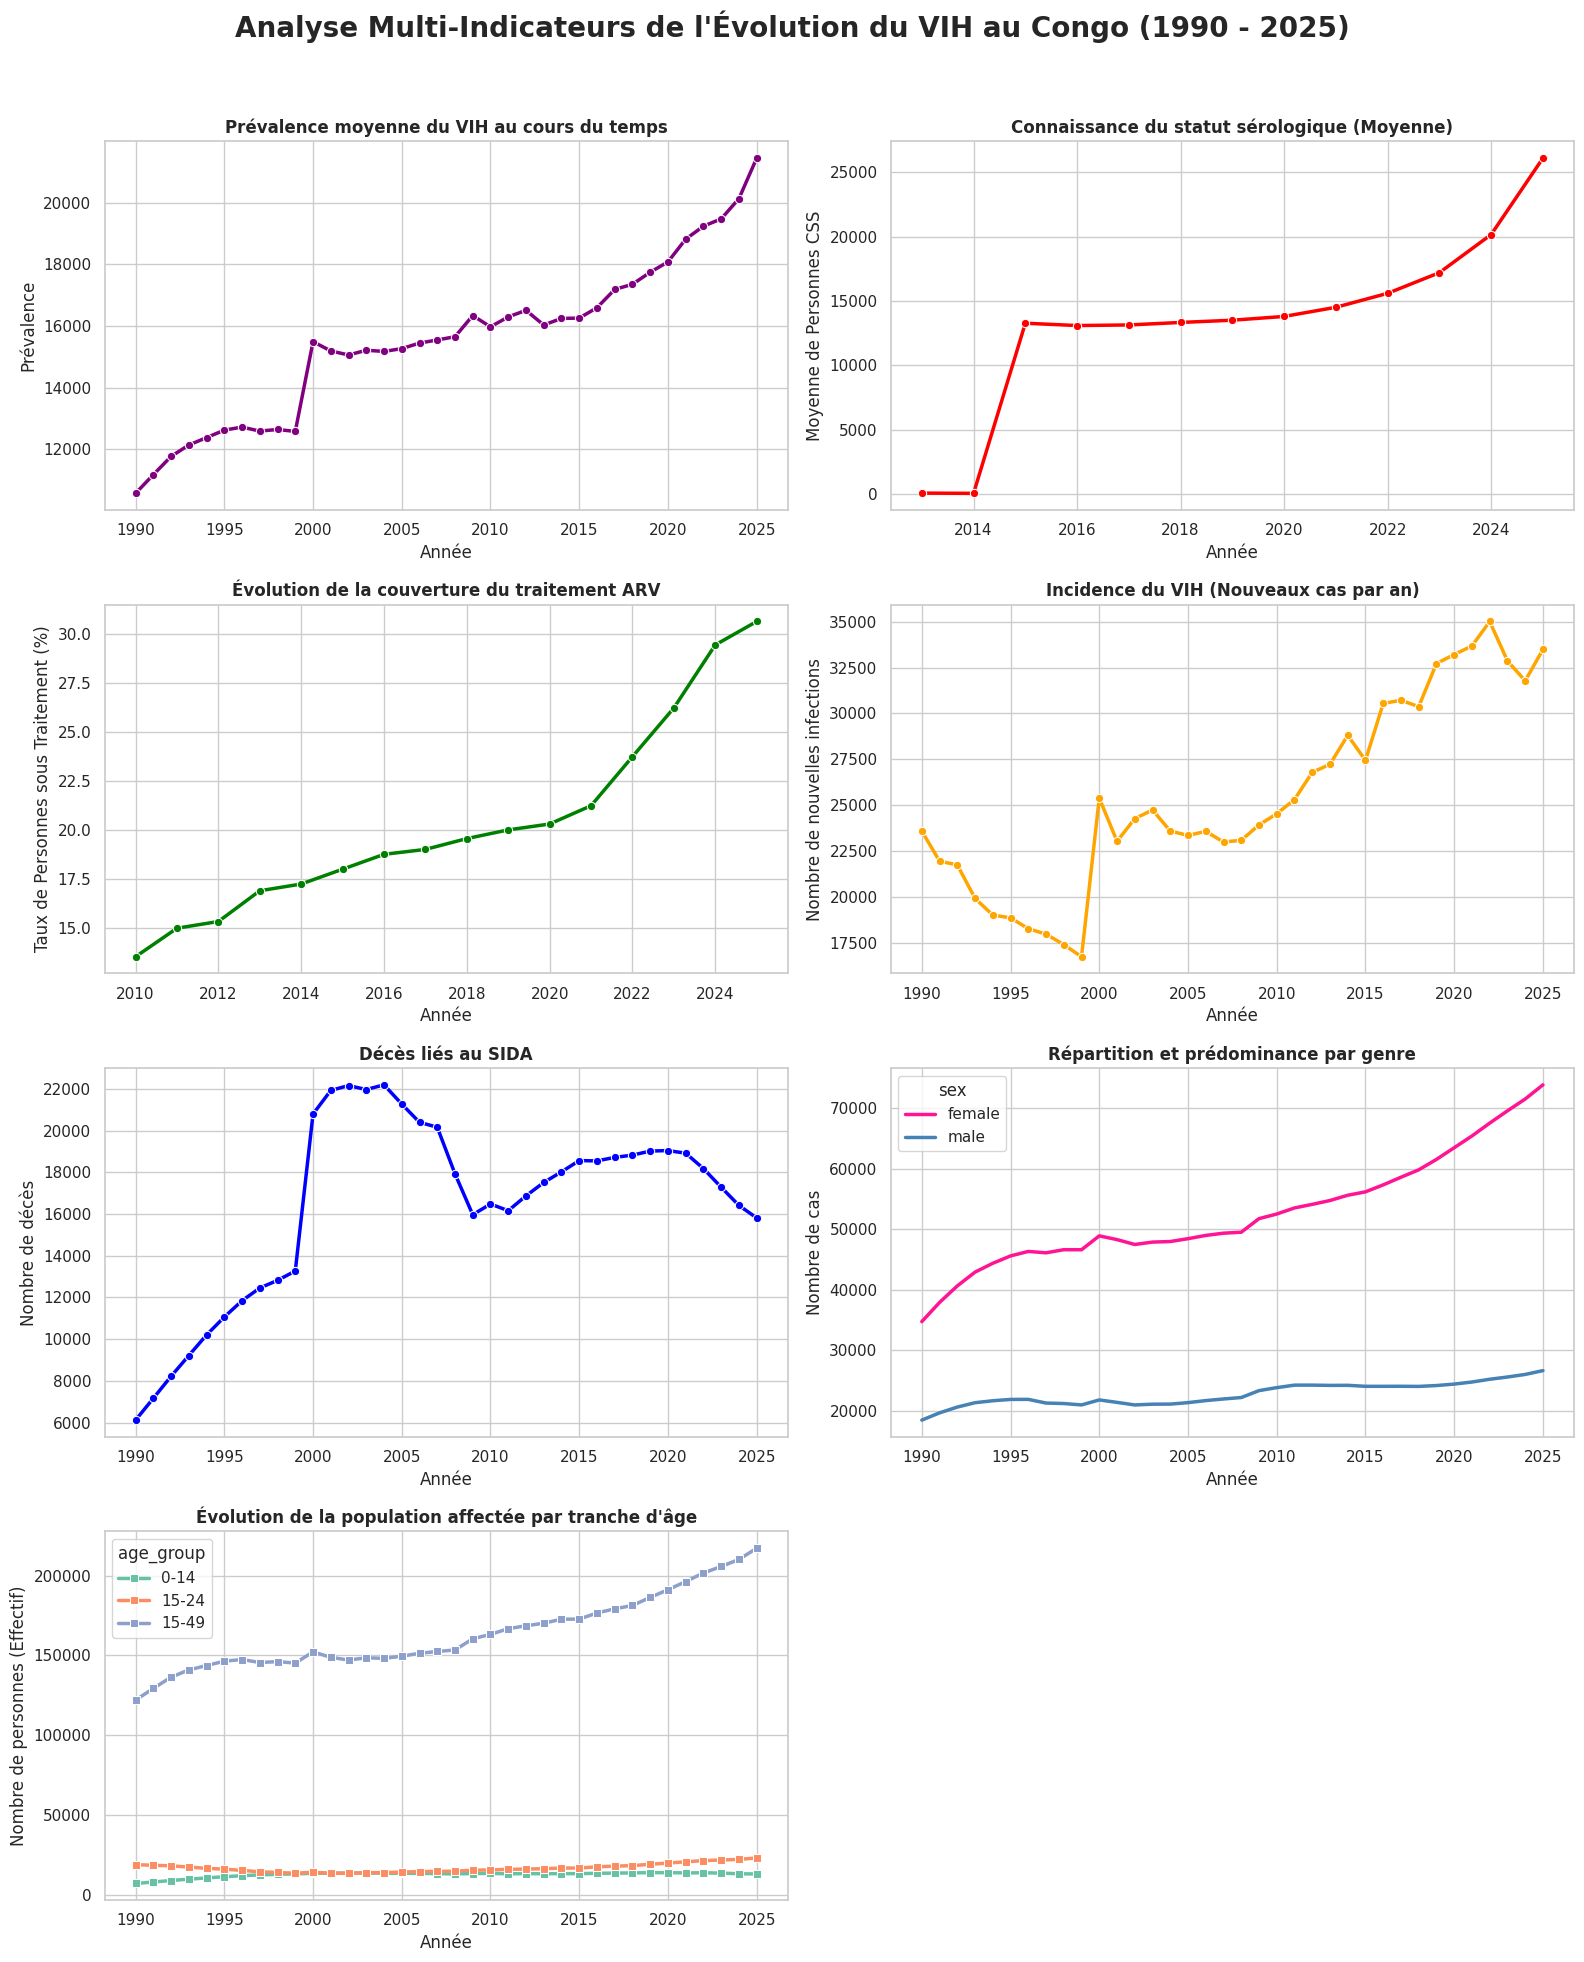

In [22]:
# ==============================================================================
# ANALYSE ET VISUALISATION DES DONNEES
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle("Analyse Multi-Indicateurs de l'Évolution du VIH au Congo (1990 - 2025)",
             fontsize=20, fontweight='bold', y=0.98)

# GRAPHIQUE I: Prévalence en moyenne du VIH
sns.lineplot(ax=axes[0,0], data=preva_trend, x="year", y="value", marker="o", color="purple", linewidth=2.5)
axes[0,0].set_title("Prévalence moyenne du VIH au cours du temps", fontweight="bold", fontsize=12)
axes[0,0].set_ylabel("Prévalence")
axes[0,0].set_xlabel("Année")

# GRAPHIQUE II: Taux de personnes connaissant leur statut sérologique
sns.lineplot(ax=axes[0,1], data=testing_trend, x="year", y="value", marker="o", color="red", linewidth=2.5)
axes[0,1].set_title("Connaissance du statut sérologique (Moyenne)", fontweight="bold", fontsize=12)
axes[0,1].set_ylabel("Moyenne de Personnes CSS")
axes[0,1].set_xlabel("Année")

# GRAPHIQUE III: Prise en charge médicale
sns.lineplot(ax=axes[1,0], data=arv_trend, x="year", y="value", marker="o", color="green", linewidth=2.5)
axes[1,0].set_title("Évolution de la couverture du traitement ARV", fontweight="bold", fontsize=12)
axes[1,0].set_ylabel("Taux de Personnes sous Traitement (%)")
axes[1,0].set_xlabel("Année")

# GRAPHIQUE IV: Incidence du VIH (Nouveaux cas)
sns.lineplot(ax=axes[1,1], data=incidence_trend, x="year", y="value", marker="o", color="orange", linewidth=2.5)
axes[1,1].set_title("Incidence du VIH (Nouveaux cas par an)", fontweight="bold", fontsize=12)
axes[1,1].set_ylabel("Nombre de nouvelles infections")
axes[1,1].set_xlabel("Année")

# GRAPHIQUE V: Impact sur la mortalité (Décès liés au SIDA)
sns.lineplot(ax=axes[2,0], data=deaths_trend, x="year", y="value", marker="o", color="blue", linewidth=2.5)
axes[2,0].set_title("Décès liés au SIDA", fontweight="bold", fontsize=12)
axes[2,0].set_ylabel("Nombre de décès")
axes[2,0].set_xlabel("Année")

# GRAPHIQUE VI: Prédominance de Genre
sns.lineplot(ax=axes[2,1], data=gender_trend, x="year", y="value", hue="sex", palette={"male":"steelblue", "female":"deeppink"}, linewidth=2.5)
axes[2,1].set_title("Répartition et prédominance par genre", fontweight="bold", fontsize=12)
axes[2,1].set_ylabel("Nombre de cas")
axes[2,1].set_xlabel("Année")

# GRAPHIQUE VII: Structure par tranche d'âge (Optimisé avec des courbes pour gérer la densité de données)
sns.lineplot(ax=axes[3,0], data=age_trend, x="year", y="value", hue="age_group", palette="Set2", linewidth=2.5, marker="s")
axes[3,0].set_title("Évolution de la population affectée par tranche d'âge", fontweight="bold", fontsize=12)
axes[3,0].set_ylabel("Nombre de personnes (Effectif)")
axes[3,0].set_xlabel("Année")

fig.delaxes(axes[3,1])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()